# 07 MiniRocket

**Goal:** train MiniRocket on the raw 5 m windows (from 06) and compare it with the random forest, using the same road split and metrics.

**Why MiniRocket:** it is made for time series classification. It looks at the raw signal shape with thousands of small random filters, instead of using features we choose by hand (like std).

In [1]:
""" import sys
print(sys.executable)
!"{sys.executable}" -m pip install sktime numba """

' import sys\nprint(sys.executable)\n!"{sys.executable}" -m pip install sktime numba '

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Checking that sktime is installed, and which version we have.
import sktime
from sktime.transformations.rocket import MiniRocketMultivariate
from sklearn.linear_model import RidgeClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
print("sktime version:", sktime.__version__)

sktime version: 1.2.0


In [3]:
# Loading the raw windows we built in 06.
# Shape: (windows, sensors, time steps) -> this is the shape sktime expects (channels first).
X_raw = np.load("data_features/raw_windows_5m.npy").astype(np.float32)

# For every window: which drive and road it comes from, and whether it is a bump (1) or not (0).
raw_index = pd.read_csv("data_features/raw_windows_index.csv")

print("X_raw shape:", X_raw.shape)
print("raw_index shape:", raw_index.shape)

X_raw shape: (2729, 7, 100)
raw_index shape: (2729, 4)


In [4]:
# The road we test on. The model never sees this road during training.
test_road = "Iisingintie"

# True for windows from the test road, False for all the others.
is_test = (raw_index["road"] == test_road).to_numpy()

# Splitting the signals (X) and the answers (y).
# ~ means "not", so ~is_test = the windows from the other two roads.
X_train = X_raw[~is_test]
X_test = X_raw[is_test]
y_train = raw_index["is_bump"].to_numpy()[~is_test]
y_test = raw_index["is_bump"].to_numpy()[is_test]

print("Train:", X_train.shape, " bump share:", round(y_train.mean(), 2))
print("Test: ", X_test.shape, " bump share:", round(y_test.mean(), 2))

Train: (916, 7, 100)  bump share: 0.19
Test:  (1813, 7, 100)  bump share: 0.19


In [5]:
# ---- Step 1: MiniRocket turns every window into ~10,000 numbers ----
minirocket = MiniRocketMultivariate(random_state=101)

# fit = MiniRocket sets up its filters, using the TRAINING windows only.
minirocket.fit(X_train)

# transform = describe every window with those filters.
X_train_feat = minirocket.transform(X_train)
X_test_feat = minirocket.transform(X_test)

print("Before MiniRocket:", X_train.shape)
print("After MiniRocket: ", X_train_feat.shape)

# ---- Step 2: scale the numbers (as in the documentation) ----
scaler = StandardScaler(with_mean=False)
X_train_feat = scaler.fit_transform(X_train_feat)
X_test_feat = scaler.transform(X_test_feat)

# ---- Step 3: the classifier decides bump / no bump ----
classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10), class_weight="balanced")
classifier.fit(X_train_feat, y_train)

# Predicting 0/1 for the test road.
y_pred = classifier.predict(X_test_feat)

# A score for every window: above 0 = bump, below 0 = no bump. Bigger = more sure.
y_score = classifier.decision_function(X_test_feat)

Before MiniRocket: (916, 7, 100)
After MiniRocket:  (916, 9996)


In [6]:
# ROC-AUC: how well the scores separate bumps from non-bumps (0.5 = guessing, 1.0 = perfect).
print("ROC-AUC:", round(roc_auc_score(y_test, y_score), 2))

# Precision, recall and f1 for both classes. The "1" row is the bump class.
print(classification_report(y_test, y_pred, zero_division=0))

ROC-AUC: 0.66
              precision    recall  f1-score   support

           0       0.86      0.84      0.85      1465
           1       0.39      0.42      0.41       348

    accuracy                           0.76      1813
   macro avg       0.63      0.63      0.63      1813
weighted avg       0.77      0.76      0.77      1813



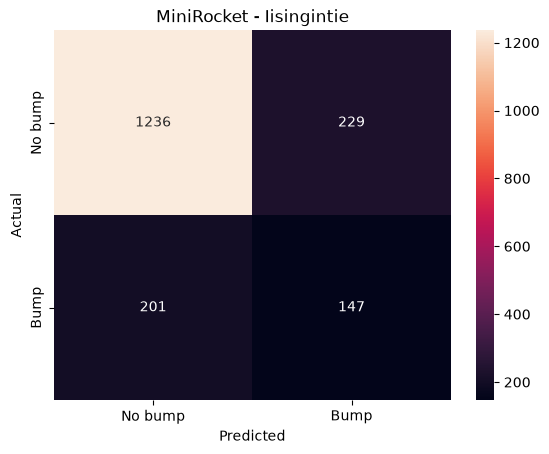

In [7]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No bump", "Bump"],
    yticklabels=["No bump", "Bump"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MiniRocket - " + test_road)
plt.show()

### All three roads (leave-one-road-out)

Same steps as above, repeated with every road as the test road once. Predictions are saved in the same format as the random forest, for the comparison in 09.

In [8]:
from sklearn.metrics import recall_score, precision_score, f1_score

results = []          # one row of scores per test road
all_predictions = []  # the predictions for every window, to save at the end

for test_road in raw_index["road"].unique():

    # ---- Split (same as cell 3) ----
    is_test = (raw_index["road"] == test_road).to_numpy()
    X_train = X_raw[~is_test]
    X_test = X_raw[is_test]
    y_train = raw_index["is_bump"].to_numpy()[~is_test]
    y_test = raw_index["is_bump"].to_numpy()[is_test]

    # ---- Model (same as cell 4) ----
    minirocket = MiniRocketMultivariate(random_state=101)
    minirocket.fit(X_train)
    X_train_feat = minirocket.transform(X_train)
    X_test_feat = minirocket.transform(X_test)

    scaler = StandardScaler(with_mean=False)
    X_train_feat = scaler.fit_transform(X_train_feat)
    X_test_feat = scaler.transform(X_test_feat)

    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 6, 10), class_weight="balanced")
    classifier.fit(X_train_feat, y_train)
    y_pred = classifier.predict(X_test_feat)
    y_score = classifier.decision_function(X_test_feat)

    # ---- Scores for this road ----
    cm = confusion_matrix(y_test, y_pred)
    results.append({
        "test_road": test_road,
        "recall": recall_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, y_score),
        "false_alarms": cm[0, 1],
        "alpha": classifier.alpha_,
    })

    # ---- Keep the predictions for this road ----
    pred_table = raw_index[is_test].copy()
    pred_table["pred"] = y_pred
    pred_table["prob"] = y_score
    all_predictions.append(pred_table)

    print("done:", test_road)

results = pd.DataFrame(results)
print(results.round(2))
print("average f1:", round(results["f1"].mean(), 2), " average auc:", round(results["auc"].mean(), 2))

done: Iisingintie
done: Kaittiaisentie
done: sinetänsalmentie
          test_road  recall  precision   f1   auc  false_alarms    alpha
0       Iisingintie    0.51       0.33  0.4  0.67           363  10000.0
1    Kaittiaisentie    0.87       0.18  0.3  0.91           116  10000.0
2  sinetänsalmentie    0.36       0.80  0.5  0.65            13  10000.0
average f1: 0.4  average auc: 0.74


In [9]:
predictions = pd.concat(all_predictions)
predictions.to_csv("predictions/predictions_minirocket.csv", index=False)
print(predictions.shape)

(2729, 6)


### Result: MiniRocket (leave-one-road-out)

The Ridge classifier chose alpha = 1000, the edge of the default range (0.001–1000), in every round. After widening the range to 10⁶ it chose 10,000 (inside the range), so this is the fair result:

| Test road | F1 | AUC | False alarms |
|---|---|---|---|
| Iisingintie | 0.40 | 0.67 | 363 |
| Kaittiaisentie | 0.30 | 0.91 | 116 |
| sinetänsalmentie | 0.50 | 0.65 | 13 |
| **Average** | **0.40** | **0.74** | |

- Ranking (AUC 0.74) is close to the random forest (0.76), but at the default threshold MiniRocket gives many more false alarms, so its F1 is lower (0.40 vs 0.44).
- Strong regularization was needed (alpha 10,000): with ~1000–2000 training windows and ~10,000 features per window, the model overfits easily.
- Lesson: when a tuned value lands at the edge of its range, widen the range.

## Arsenal

Arsenal = many ROCKET models (25 by default) that vote together. We test it in two setups:
1. our road split (comparable with the other models)
2. Jeremy's starter split (test drive m792, training on the other drives, including the rest of the same road)

### one function for both setups

In [13]:
from sktime.classification.kernel_based import Arsenal
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix

def train_arsenal(is_train, is_test):
    # Select the windows for training and testing.
    X_train = X_raw[is_train]
    X_test = X_raw[is_test]
    y_train = raw_index["is_bump"].to_numpy()[is_train]
    y_test = raw_index["is_bump"].to_numpy()[is_test]

    # 25 ROCKET models with 2000 filters each, voting together.
    model = Arsenal(num_kernels=2000, n_estimators=25, random_state=101, n_jobs=-1)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    scores = {
        "accuracy": accuracy_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, y_prob),
        "false_alarms": cm[0, 1],
        "bump_share_test": y_test.mean(),
    }
    return scores, y_pred, y_prob

### setup 1, our road split

In [14]:
road_results = []
all_predictions = []

for test_road in raw_index["road"].unique():
    is_test = (raw_index["road"] == test_road).to_numpy()
    is_train = ~is_test
    scores, y_pred, y_prob = train_arsenal(is_train, is_test)

    scores["test_road"] = test_road
    road_results.append(scores)

    pred_table = raw_index[is_test].copy()
    pred_table["pred"] = y_pred
    pred_table["prob"] = y_prob
    all_predictions.append(pred_table)

    print("done:", test_road)

road_results = pd.DataFrame(road_results)
print(road_results.round(2))
print("average f1:", round(road_results["f1"].mean(), 2), " average auc:", round(road_results["auc"].mean(), 2))

predictions = pd.concat(all_predictions)
predictions.to_csv("predictions/predictions_arsenal.csv", index=False)
print(predictions.shape)

done: Iisingintie
done: Kaittiaisentie
done: sinetänsalmentie
   accuracy  recall  precision    f1   auc  false_alarms  bump_share_test  \
0      0.81    0.35       0.49  0.41  0.66           128             0.19   
1      0.95    0.70       0.50  0.58  0.91            21             0.05   
2      0.68    0.32       0.94  0.48  0.67             3             0.46   

          test_road  
0       Iisingintie  
1    Kaittiaisentie  
2  sinetänsalmentie  
average f1: 0.49  average auc: 0.75
(2729, 6)


### setup 2, Jeremy's starter split

In [15]:
# Test = drive m792. Training = all other drives of Iisingintie and sinetänsalmentie
# (Kaittiaisentie is left out, as in the prof's notebook).
is_test = raw_index["drive"].str.contains("m792").to_numpy()
is_train = (~is_test) & (raw_index["road"] != "Kaittiaisentie").to_numpy()

prof_scores, _, _ = train_arsenal(is_train, is_test)
print(pd.Series(prof_scores).round(2))

accuracy           0.68
recall             0.49
precision          1.00
f1                 0.65
auc                0.79
false_alarms       0.00
bump_share_test    0.62
dtype: float64


## Summary of 07

**Models:** MiniRocket (one model, Ridge classifier) and Arsenal (25 ROCKET models voting). Both use the raw 5 m windows from 06 (7 sensor channels × 100 points, normalized per drive) and the same road split as the random forest.

| Model | Avg F1 | Avg AUC | False alarms (total) |
|---|---|---|---|
| Random forest (05, for comparison) | 0.44 | 0.76 | 189 |
| MiniRocket | 0.40 | 0.74 | 492 |
| **Arsenal** | **0.49** | **0.75** | **152** |

**What we learned:**
- sktime 1.2.0 with the newest scikit-learn: `make_pipeline` failed with MiniRocket, so its steps are written by hand. Arsenal worked directly.
- MiniRocket needed strong regularization (alpha 10,000). A tuned value at the edge of its range means the range is too narrow.
- Arsenal is the best model so far: the voting of 25 models reduces overfitting, which gives higher precision and fewer false alarms.
- Accuracy is misleading here: on Kaittiaisentie (5% bumps), "always no bump" already gets 95% accuracy.

**Saved:** `predictions/predictions_minirocket.csv`, `predictions/predictions_arsenal.csv`

**Next:** 09 (comparison of all models at bump level), then 10 (tuning Arsenal).